## HELPFULL INFO

the dataset comes from https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients


the data set has 30000 records


the data was colected from Taiwan useing datamineing 


col 1: Amount of the given credit (NT dollar): it includes both the individual consumer credit and his/her family (supplementary) credit.


col 2: Gender (1 = male; 2 = female).


col 3: Education (1 = graduate school; 2 = university; 3 = high school; 4 = others).


col 4: Marital status (1 = married; 2 = single; 3 = others).


col 5: Age (year).


col6 - col11: History of past payment. We tracked the past monthly payment records (from April to September, 2005) as follows: col 6 = the repayment status in September, 2005; col 7 = the repayment status in August, 2005; . . .;col 11 = the repayment status in April, 2005. The measurement scale for the repayment status is: -1 = pay duly; 1 = payment delay for one month; 2 = payment delay for two months; . . .; 8 = payment delay for eight months; 9 = payment delay for nine months and above.


col 12 - col 17: Amount of bill statement (NT dollar). col 12 = amount of bill statement in September, 2005; col 13 = amount of bill statement in August, 2005; . . .; col 17 = amount of bill statement in April, 2005.


col 18-col 23: Amount of previous payment (NT dollar). col 18 = amount paid in September, 2005; col 19 = amount paid in August, 2005; . . .;col 23 = amount paid in April, 2005.

## imports

In [402]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC, SVC
from sklearn.metrics import (
    roc_auc_score, accuracy_score, precision_score, 
    recall_score, f1_score, ConfusionMatrixDisplay
)
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

## Loading the Data

In [403]:
df = pd.read_csv("data/default of credit card clients.csv")

## DATA CLEANING

In [404]:
# Clean column names (strip any accidental whitespaces)
df.columns = df.columns.str.strip()

# Identify target column dynamically to prevent naming mismatches
target_col = "default payment next month"
if target_col not in df.columns:
    target_col = [c for c in df.columns if 'default' in c.lower()][0]

print(f"Target variable identified as: '{target_col}'")
print(f"Initial dataset shape: {df.shape}")

# ==========================================
# DROP ALL UNKNOWN / INVALID CATEGORICAL CODES
# ==========================================
# This removes undocumented codes:
# - EDUCATION outside 1-4 (drops 0, 5, 6)
# - MARRIAGE outside 1-3 (drops 0)
# - SEX outside 1-2
df = df[
    df['EDUCATION'].isin([1, 2, 3, 4]) & 
    df['MARRIAGE'].isin([1, 2, 3]) & 
    df['SEX'].isin([1, 2])
]

print(f"Remaining rows after cleanup: {len(df)}")

# Separate features (X) and target (y). Drop 'ID' as it's not predictive.
X = df.drop(columns=["ID", target_col])
y = df[target_col]

Target variable identified as: 'default payment next month'
Initial dataset shape: (30000, 25)
Remaining rows after cleanup: 29601


## Define Feature Types

In [405]:
categorical_cols = ["SEX", "EDUCATION", "MARRIAGE", "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
quantitative_cols = [col for col in X.columns if col not in categorical_cols]

## Build Preprocessor

In [406]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), quantitative_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

## Train/Test Split

In [407]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

## Define Models to Test

In [408]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Linear SVM": LinearSVC(max_iter=5000, random_state=42, dual=False),
    "RBF SVM": SVC(kernel='rbf', probability=True, random_state=42),
    "Polynomial SVM": SVC(kernel='poly', degree=3, probability=True, random_state=42)
}

## Train, Evaluate, and Compare Model

## Train, Evaluate, and Compare Model with a class_weight = balanced

In [409]:
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)

# 1. Load Data
df = pd.read_csv("data/default of credit card clients.csv")
df.columns = df.columns.str.strip()

target_col = "default payment next month"
if target_col not in df.columns:
    target_col = [c for c in df.columns if 'default' in c.lower()][0]

X = df.drop(columns=["ID", target_col])
y = df[target_col]

# 2. Define Feature Types
categorical_cols = ["SEX", "EDUCATION", "MARRIAGE", "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
quantitative_cols = [col for col in X.columns if col not in categorical_cols]

# 3. Build Preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), quantitative_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

# 4. Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 5. Define All 4 Models (Balanced + Unbalanced)
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Logistic Regression (Balanced)": LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    "Linear SVM": LinearSVC(max_iter=5000, random_state=42, dual=False),
    "Linear SVM (Balanced)": LinearSVC(class_weight='balanced', max_iter=5000, random_state=42, dual=False)
}

# 6. Train, Evaluate, and Compare Models
results = []
trained_pipelines = {}

for name, model in models.items():
    print(f"\n--- Training {name} ---")
    
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    
    start_time = time.time()
    pipeline.fit(X_train, y_train)
    train_time = time.time() - start_time
    
    # Save the pipeline reference for plotting confusion matrices later
    trained_pipelines[name] = pipeline
    
    start_time = time.time()
    y_pred = pipeline.predict(X_test)
    predict_time = time.time() - start_time
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    
    try:
        if hasattr(pipeline, "predict_proba"):
            y_prob = pipeline.predict_proba(X_test)[:, 1]
        else:
            y_prob = pipeline.decision_function(X_test)
        roc = roc_auc_score(y_test, y_prob)
    except Exception:
        roc = np.nan

    results.append({
        "Model": name,
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1-Score": round(f1, 4),
        "ROC-AUC": round(roc, 4),
        "Train Time (s)": round(train_time, 2),
        "Predict Time (s)": round(predict_time, 2)
    })




--- Training Logistic Regression ---

--- Training Logistic Regression (Balanced) ---

--- Training Linear SVM ---

--- Training Linear SVM (Balanced) ---


## CHARTS


--- Training Logistic Regression ---

--- Training Logistic Regression (Balanced) ---

--- Training Linear SVM ---

--- Training Linear SVM (Balanced) ---

MODEL PERFORMANCE COMPARISON
                         Model  Accuracy  Precision  Recall  F1-Score  Train Time (s)  Predict Time (s)
           Logistic Regression    0.8168     0.6615  0.3519    0.4594            0.17              0.01
Logistic Regression (Balanced)    0.7735     0.4893  0.5531    0.5193            0.27              0.01
                    Linear SVM    0.8165     0.6601  0.3512    0.4584            0.33              0.01
         Linear SVM (Balanced)    0.7767     0.4955  0.5448    0.5190            0.26              0.01

Generating charts...


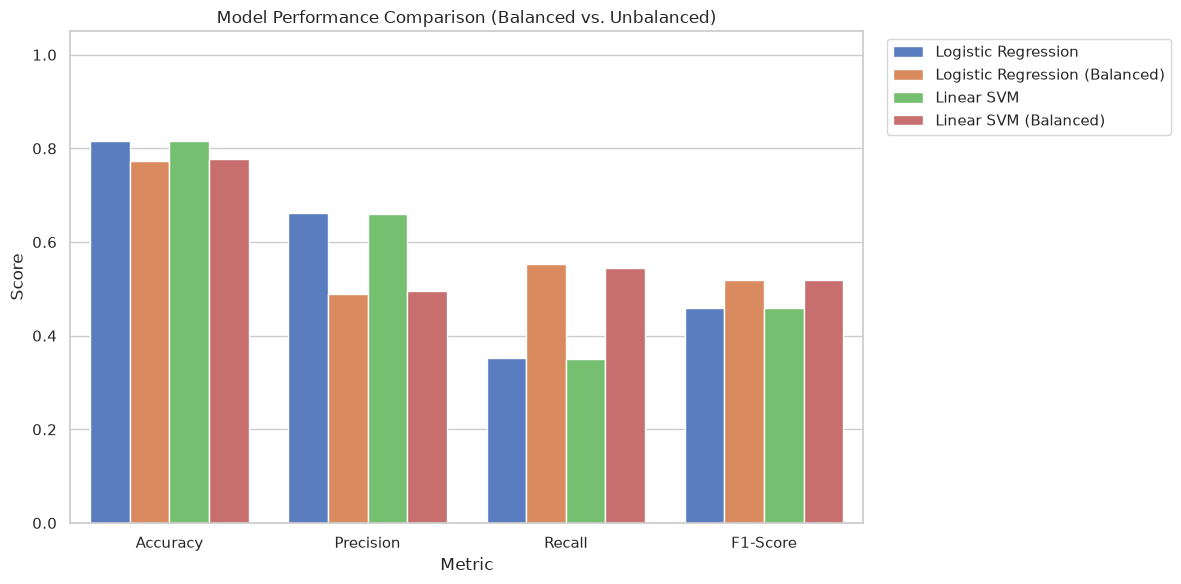

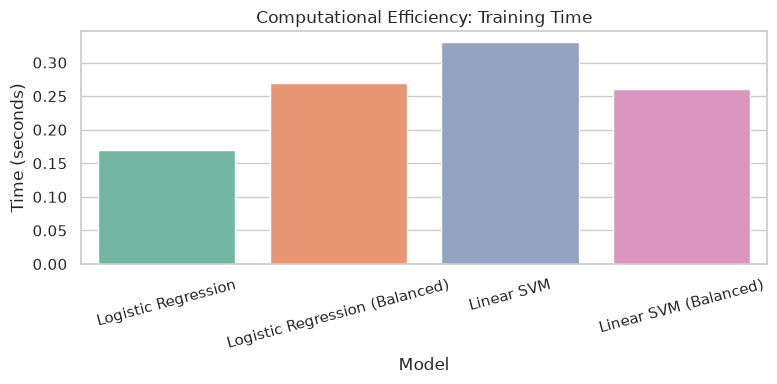

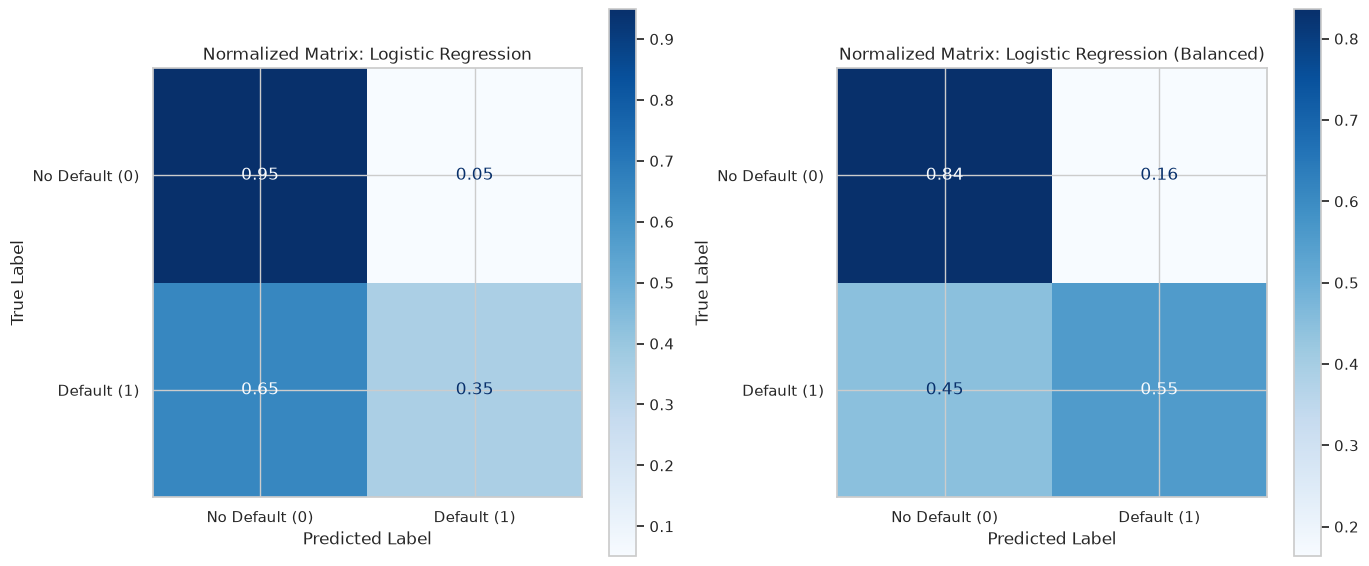

In [410]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)

# 1. Load Data
df = pd.read_csv("data/default of credit card clients.csv")
df.columns = df.columns.str.strip()

target_col = "default payment next month"
if target_col not in df.columns:
    target_col = [c for c in df.columns if 'default' in c.lower()][0]

X = df.drop(columns=["ID", target_col])
y = df[target_col]

# 2. Define Feature Types
categorical_cols = ["SEX", "EDUCATION", "MARRIAGE", "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
quantitative_cols = [col for col in X.columns if col not in categorical_cols]

# 3. Build Preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), quantitative_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

# 4. Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 5. Define All 4 Models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Logistic Regression (Balanced)": LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    "Linear SVM": LinearSVC(max_iter=5000, random_state=42, dual=False),
    "Linear SVM (Balanced)": LinearSVC(class_weight='balanced', max_iter=5000, random_state=42, dual=False)
}

# 6. Train, Evaluate, and Compare Models
results = []
trained_pipelines = {}

for name, model in models.items():
    print(f"\n--- Training {name} ---")
    
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    
    start_time = time.time()
    pipeline.fit(X_train, y_train)
    train_time = time.time() - start_time
    
    trained_pipelines[name] = pipeline
    
    start_time = time.time()
    y_pred = pipeline.predict(X_test)
    predict_time = time.time() - start_time
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    results.append({
        "Model": name,
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1-Score": round(f1, 4),
        "Train Time (s)": round(train_time, 2),
        "Predict Time (s)": round(predict_time, 2)
    })

# Display Results Table
results_df = pd.DataFrame(results)
print("\n==============================")
print("MODEL PERFORMANCE COMPARISON")
print("==============================")
print(results_df.to_string(index=False))

# ==========================================
# 7. GENERATE CHARTS
# ==========================================
print("\nGenerating charts...")

# Chart 1: Performance Metrics Grouped Bar Chart
metrics_cols = ["Accuracy", "Precision", "Recall", "F1-Score"]
plot_df = results_df.melt(
    id_vars=["Model"], 
    value_vars=metrics_cols, 
    var_name="Metric", 
    value_name="Score"
)

plt.figure(figsize=(12, 6))
sns.barplot(data=plot_df, x="Metric", y="Score", hue="Model", palette="muted")
plt.title("Model Performance Comparison (Balanced vs. Unbalanced)")
plt.ylim(0, 1.05)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Chart 2: Training Time Comparison Bar Chart (Restored!)
plt.figure(figsize=(8, 4))
sns.barplot(data=results_df, x="Model", y="Train Time (s)", palette="Set2")
plt.title("Computational Efficiency: Training Time")
plt.ylabel("Time (seconds)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Chart 3: Side-by-Side Normalized Confusion Matrices with Labeled Axes
class_names = ['No Default (0)', 'Default (1)']
matrix_models = ["Logistic Regression", "Logistic Regression (Balanced)"]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, name in zip(axes, matrix_models):
    ConfusionMatrixDisplay.from_estimator(
        trained_pipelines[name], 
        X_test, 
        y_test, 
        normalize='true', 
        cmap='Blues', 
        ax=ax, 
        values_format='.2f',
        display_labels=class_names
    )
    ax.set_title(f"Normalized Matrix: {name}")
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')

plt.tight_layout()
plt.show()








## Which Variables are Most Predictive


--- TOP FACTORS INCREASING DEFAULT RISK ---
           Readable Feature  Coefficient
PAY_0 Status: 2-month delay     1.047619
PAY_0 Status: 3-month delay     0.962352
PAY_3 Status: 6-month delay     0.686818
PAY_2 Status: 5-month delay     0.649495
PAY_6 Status: 4-month delay     0.547908
      Education: University     0.546779
 Education: Graduate School     0.495422
     Education: High School     0.457625
           Marriage: Others     0.427093
PAY_0 Status: 7-month delay     0.401346

--- TOP FACTORS DECREASING DEFAULT RISK ---
                           Readable Feature  Coefficient
                          Education: Others    -0.355682
                PAY_3 Status: 4-month delay    -0.390000
                PAY_2 Status: 1-month delay    -0.427284
        PAY_6 Status: Revolving credit used    -0.462232
          PAY_0 Status: Paid duly (on time)    -0.577865
                PAY_5 Status: 4-month delay    -0.612659
                PAY_2 Status: 4-month delay    -0.646805
   

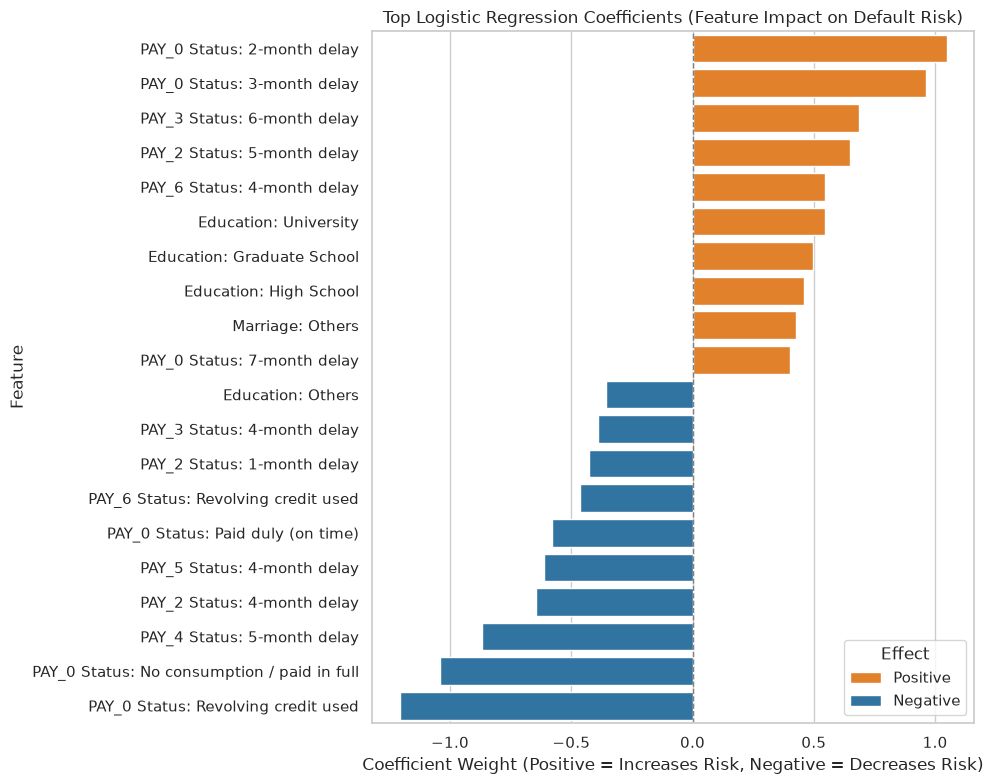

In [ ]:
def clean_feature_name(feat):
    """Cleanly maps one-hot encoded features, properly handling negative status codes. Returns None for unknowns to drop them."""
    if "_" in feat:
        parts = feat.rsplit("_", 1)
        col, val = parts[0], parts[1]
        
        edu_labels = {'1': 'Graduate School', '2': 'University', '3': 'High School', '4': 'Others'}
        sex_labels = {'1': 'Male', '2': 'Female'}
        mar_labels = {'1': 'Married', '2': 'Single', '3': 'Others'}
        pay_labels = {
            '-2': 'No consumption / paid in full', '-1': 'Paid duly (on time)', '0': 'Revolving credit used', 
            '1': '1-month delay', '2': '2-month delay', '3': '3-month delay', '4': '4-month delay', 
            '5': '5-month delay', '6': '6-month delay', '7': '7-month delay', '8': '8-month delay', '9': '9-month delay'
        }
        
        if col == "EDUCATION":
            if val not in edu_labels: return None
            return f"Education: {edu_labels[val]}"
        elif col == "SEX":
            if val not in sex_labels: return None
            return f"Sex: {sex_labels[val]}"
        elif col == "MARRIAGE":
            if val not in mar_labels: return None
            return f"Marriage: {mar_labels[val]}"
        elif col in ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]:
            return f"{col} Status: {pay_labels.get(val, val)}"
            
    return feat

# 1. Fit the model
lr_pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
])
lr_pipe.fit(X_train, y_train)

# 2. Extract feature names and match coefficients
cat_encoder = lr_pipe.named_steps['preprocessor'].named_transformers_['cat']
encoded_cat_cols = list(cat_encoder.get_feature_names_out(categorical_cols))
all_features = quantitative_cols + encoded_cat_cols

coefficients = pd.DataFrame({
    'Feature': all_features,
    'Coefficient': lr_pipe.named_steps['classifier'].coef_[0]
}).sort_values(by='Coefficient', ascending=False)

# 3. Apply cleaning function AND drop any None (unknowns)
coefficients['Readable Feature'] = coefficients['Feature'].apply(clean_feature_name)
coefficients = coefficients.dropna(subset=['Readable Feature']).reset_index(drop=True)

readable_coefficients = coefficients[['Readable Feature', 'Coefficient']].copy()

print("\n--- TOP FACTORS INCREASING DEFAULT RISK ---")
print(readable_coefficients.head(10).to_string(index=False))

print("\n--- TOP FACTORS DECREASING DEFAULT RISK ---")
print(readable_coefficients.tail(10).to_string(index=False))

# 4. Plot using 'hue' to prevent alphabetical color-mismatching
plot_data = pd.concat([readable_coefficients.head(10), readable_coefficients.tail(10)]).copy()
plot_data['Sign'] = plot_data['Coefficient'].apply(lambda c: 'Positive' if c > 0 else 'Negative')

plt.figure(figsize=(10, 8))
sns.barplot(
    data=plot_data, 
    x='Coefficient', 
    y='Readable Feature', 
    hue='Sign',
    palette={'Positive': '#ff7f0e', 'Negative': '#1f77b4'},
    dodge=False
)

plt.axvline(0, color='gray', linestyle='--', linewidth=1)
plt.title('Top Logistic Regression Coefficients (Feature Impact on Default Risk)', fontsize=12)
plt.xlabel('Coefficient Weight (Positive = Increases Risk, Negative = Decreases Risk)')
plt.ylabel('Feature')
plt.legend(title='Effect', loc='lower right')
plt.tight_layout()
plt.show()

